In [2]:
import duckdb
import matplotlib.pyplot as plt
import seaborn as sns

con = duckdb.connect()
cars = con.read_parquet("../data/processed/clean.parquet")

### Какие марки, модели, кузова, типы топлива и КПП доминируют на рынке и как это отличается между «массовым» и «премиальным» сегментом?

In [12]:
# Массовый сегмент объединяет бюджетный и средний (цена ниже 3 млн ₽).
market_shares = con.sql("""
    WITH listings AS (
        SELECT CASE WHEN price_segment = 'Премиум' THEN 'Премиальный'
                    WHEN price_segment IN ('Бюджетный', 'Средний') THEN 'Массовый'
               END AS segment,
               brand AS "Марка",
               brand || ' ' || name AS "Модель",
               bodyType AS "Кузов", fuelType AS "Топливо", transmission AS "КПП"
        FROM cars
    ),
    categories AS (
        SELECT segment, feature, category
        FROM listings UNPIVOT INCLUDE NULLS (
            category FOR feature IN ("Марка", "Модель", "Кузов", "Топливо", "КПП")
        )
    ),
    counts AS (
        SELECT CASE WHEN GROUPING(segment) = 1 THEN 'Весь рынок'
                    ELSE segment END AS market,
               feature, COALESCE(category, 'Не указано') AS category,
               COUNT(*) AS listings
        FROM categories
        GROUP BY GROUPING SETS ((segment, feature, category), (feature, category))
    )
    SELECT *, 100.0 * listings / SUM(listings) OVER (PARTITION BY market, feature) AS share
    FROM counts
""").df()
market_shares.head()

,market,feature,category,listings,share
0,Весь рынок,Марка,HiPhi,4,0.000824
1,Весь рынок,Марка,Jetta,146,0.030063
2,Весь рынок,Марка,Hongqi,21,0.004324
3,Весь рынок,Марка,Acura,196,0.040358
4,Весь рынок,Марка,Geely,5496,1.131675


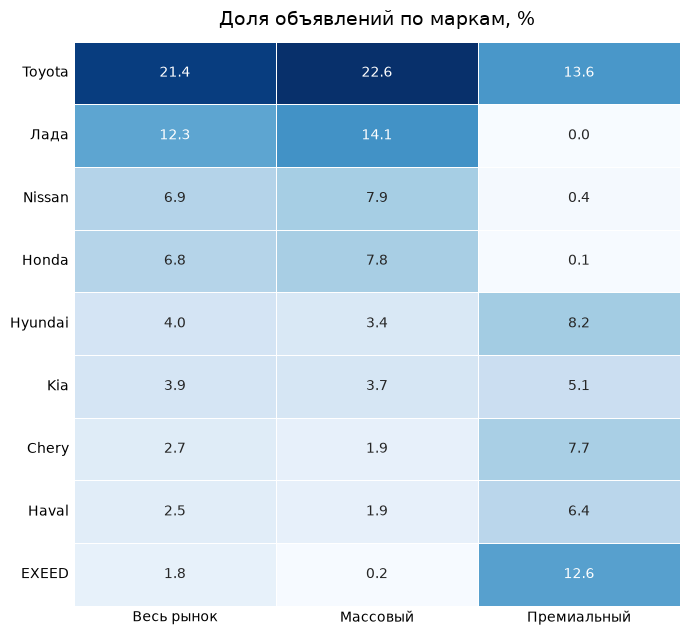

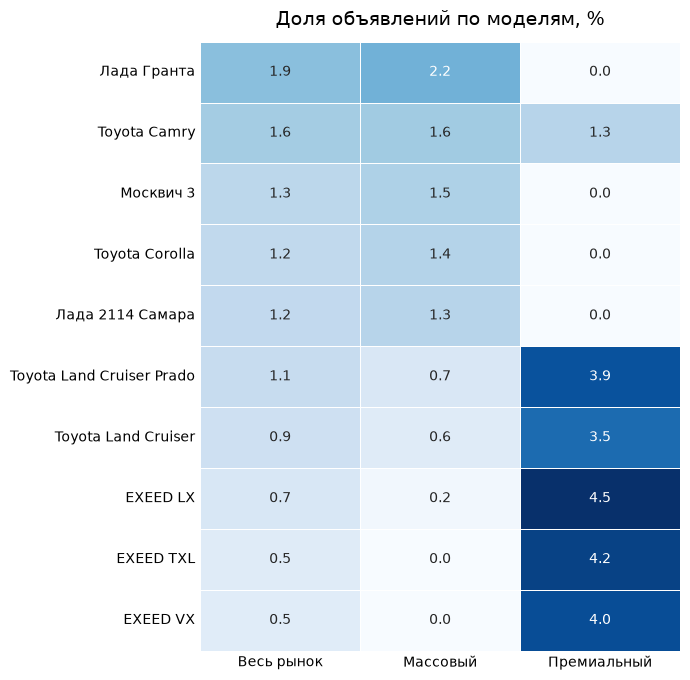

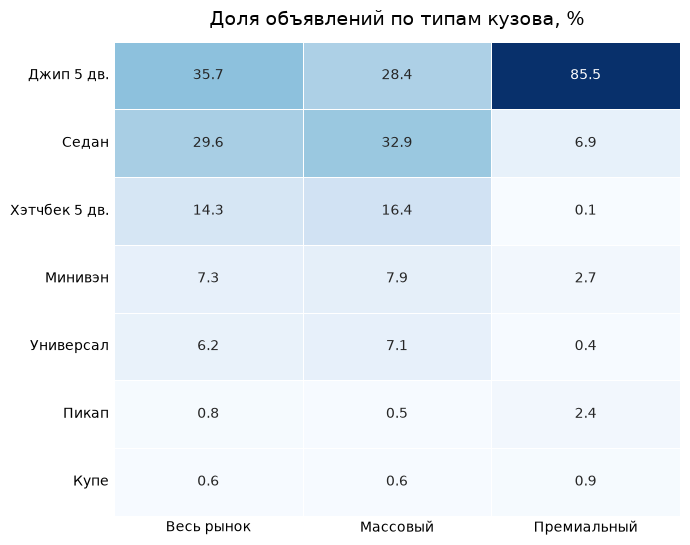

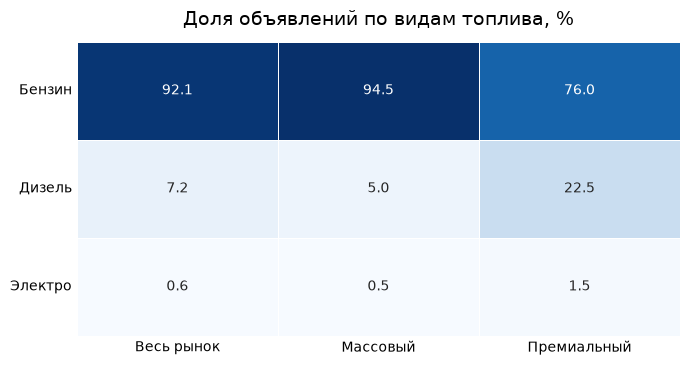

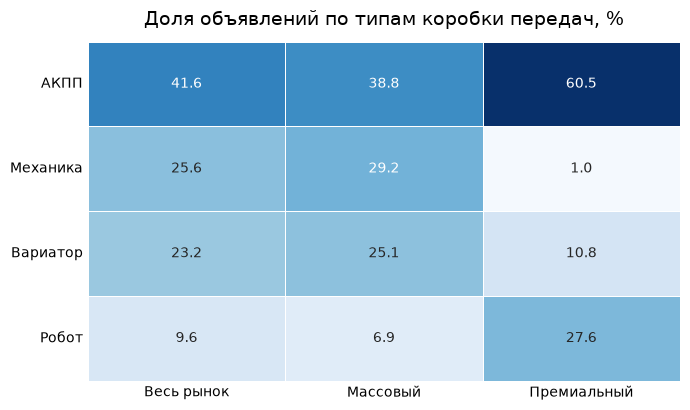

In [19]:
markets = ["Весь рынок", "Массовый", "Премиальный"]
titles = {
    "Марка": "Доля объявлений по маркам, %",
    "Модель": "Доля объявлений по моделям, %",
    "Кузов": "Доля объявлений по типам кузова, %",
    "Топливо": "Доля объявлений по видам топлива, %",
    "КПП": "Доля объявлений по типам коробки передач, %",
}
for feature in ["Марка", "Модель", "Кузов", "Топливо", "КПП"]:
    shares = (market_shares.loc[market_shares["feature"] == feature]
              .pivot(index="category", columns="market", values="share")
              .reindex(columns=markets).fillna(0))

    # В таблице - объединение пятёрок лидеров по каждому столбцу.
    leaders = shares.rank(ascending=False, method="min").le(5).any(axis=1)
    top = shares.loc[leaders].sort_values("Весь рынок", ascending=False)
    fig, ax = plt.subplots(figsize=(7, 2.4 + 0.45 * len(top)))

    sns.heatmap(top, annot=True, fmt=".1f", cmap="Blues", vmin=0, cbar=False,
                linewidths=0.5, ax=ax)
    
    ax.set_title(titles[feature], loc="center", pad=12, fontsize=14)
    ax.set(xlabel="", ylabel="")
    ax.tick_params(axis="both", length=0, labelrotation=0)
    fig.tight_layout()
    plt.show()

### Возрастной профиль рынка: средний и медианный возраст авто и доля машин старше 1, 5, 10 и 15 лет

In [11]:
age_profile = con.sql("""
    SELECT AVG(car_age) AS mean_age,
           MEDIAN(car_age) AS median_age,
           100.0 * COUNT(*) FILTER (WHERE car_age > 1) / COUNT(*) AS share_over_1,
           100.0 * COUNT(*) FILTER (WHERE car_age > 5) / COUNT(*) AS share_over_5,
           100.0 * COUNT(*) FILTER (WHERE car_age > 10) / COUNT(*) AS share_over_10,
           100.0 * COUNT(*) FILTER (WHERE car_age > 15) / COUNT(*) AS share_over_15
    FROM cars
    WHERE car_age IS NOT NULL
""").df()

age_profile.rename(columns={
    "mean_age": "Средний возраст, лет",
    "median_age": "Медианный возраст, лет",
    "share_over_1": "Старше 1 года, %",
    "share_over_5": "Старше 5 лет, %",
    "share_over_10": "Старше 10 лет, %",
    "share_over_15": "Старше 15 лет, %",
}).round(1)

,"Средний возраст, лет","Медианный возраст, лет","Старше 1 года, %","Старше 5 лет, %","Старше 10 лет, %","Старше 15 лет, %"
0,12.8,12.0,89.3,72.6,55.3,36.0


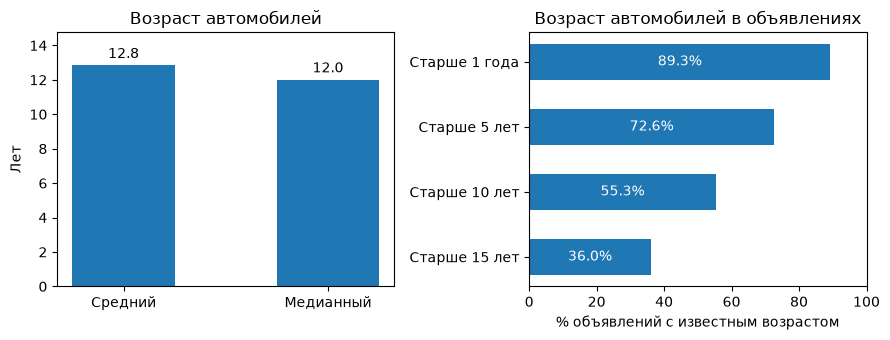

In [10]:
profile = age_profile.iloc[0]
fig, (ax_age, ax_share) = plt.subplots(1, 2, figsize=(9, 3.5))

ages = ax_age.bar(["Средний", "Медианный"], profile[["mean_age", "median_age"]], width=0.5)
ax_age.bar_label(ages, fmt="%.1f", padding=3)
ax_age.set(title="Возраст автомобилей", ylabel="Лет")
ax_age.margins(y=0.15)

labels = ["Старше 1 года", "Старше 5 лет", "Старше 10 лет", "Старше 15 лет"]
shares = profile[["share_over_1", "share_over_5", "share_over_10", "share_over_15"]]
share = ax_share.barh(labels, shares, height=0.55)
ax_share.bar_label(share, fmt="%.1f%%", label_type="center", color="white")
ax_share.invert_yaxis()
ax_share.set(title="Возраст автомобилей в объявлениях", xlabel="% объявлений с известным возрастом", xlim=(0, 100))

fig.tight_layout()
plt.show()

### Какова доля иномарок и отечественных авто и как она меняется по возрасту авто?

In [12]:
origin_shares = con.sql("""
    WITH listings AS (
        SELECT brand_origin, car_age,
               CASE WHEN car_age IS NULL THEN 'Возраст неизвестен'
                    WHEN car_age <= 1 THEN '0–1 год'
                    WHEN car_age <= 5 THEN '2–5 лет'
                    WHEN car_age <= 10 THEN '6–10 лет'
                    WHEN car_age <= 15 THEN '11–15 лет'
                    ELSE '16 лет и старше' END AS age_group
        FROM cars
        WHERE brand_origin IS NOT NULL
    )
    SELECT COALESCE(age_group, 'Все возрасты') AS "Возраст авто",
           COUNT(*) AS "Объявления",
           100.0 * COUNT(*) FILTER (WHERE brand_origin = 'Иномарка') / COUNT(*) AS "Иномарки, %",
           100.0 * COUNT(*) FILTER (WHERE brand_origin = 'Отечественная') / COUNT(*) AS "Отечественные, %"
    FROM listings
    GROUP BY GROUPING SETS ((), (age_group))
    ORDER BY GROUPING(age_group) DESC, MIN(car_age) NULLS LAST
""").df().set_index("Возраст авто")

origin_shares.round(1)

,Объявления,"Иномарки, %","Отечественные, %"
Возраст авто,,,
Все возрасты,485652,85.1,14.9
0–1 год,52085,72.0,28.0
2–5 лет,81170,92.1,7.9
6–10 лет,83645,93.0,7.0
11–15 лет,93830,91.6,8.4
16 лет и старше,174922,78.3,21.7


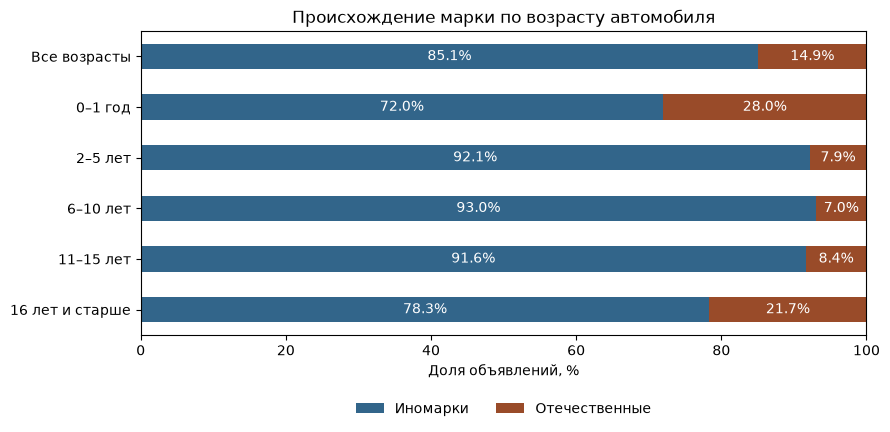

In [13]:
ax = origin_shares[["Иномарки, %", "Отечественные, %"]].plot.barh(
    stacked=True, figsize=(9, 4.5), color=["#32658a", "#994b29"]
)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", label_type="center", color="white")
ax.invert_yaxis()
ax.set(title="Происхождение марки по возрасту автомобиля",
       xlabel="Доля объявлений, %", ylabel="", xlim=(0, 100))
ax.legend(["Иномарки", "Отечественные"], loc="upper center",
          bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
ax.figure.tight_layout()
plt.show()

### Какие сочетания «кузов + топливо + КПП» встречаются чаще всего?
В рейтинг входят десять самых частых сочетаний. Доли рассчитаны среди всех объявлений, где указаны кузов, топливо и КПП.

In [14]:
top_combinations = con.sql("""
    WITH counts AS (
        SELECT bodyType, fuelType, transmission, COUNT(*) AS listings
        FROM cars
        WHERE bodyType IS NOT NULL AND fuelType IS NOT NULL AND transmission IS NOT NULL
        GROUP BY bodyType, fuelType, transmission
    )
    SELECT bodyType AS "Кузов", fuelType AS "Топливо", transmission AS "КПП",
           listings AS "Объявления",
           100.0 * listings / SUM(listings) OVER () AS "Доля, %"
    FROM counts
    ORDER BY listings DESC, bodyType, fuelType, transmission
    LIMIT 10
""").df()

top_combinations.round(1)

,Кузов,Топливо,КПП,Объявления,"Доля, %"
0,Седан,Бензин,АКПП,66610,13.7
1,Джип 5 дв.,Бензин,АКПП,59439,12.2
2,Седан,Бензин,Механика,56901,11.7
3,Джип 5 дв.,Бензин,Вариатор,42164,8.7
4,Джип 5 дв.,Бензин,Робот,32595,6.7
5,Хэтчбек 5 дв.,Бензин,Механика,24335,5.0
6,Хэтчбек 5 дв.,Бензин,Вариатор,22090,4.5
7,Джип 5 дв.,Дизель,АКПП,19901,4.1
8,Минивэн,Бензин,Вариатор,18803,3.9
9,Хэтчбек 5 дв.,Бензин,АКПП,17368,3.6


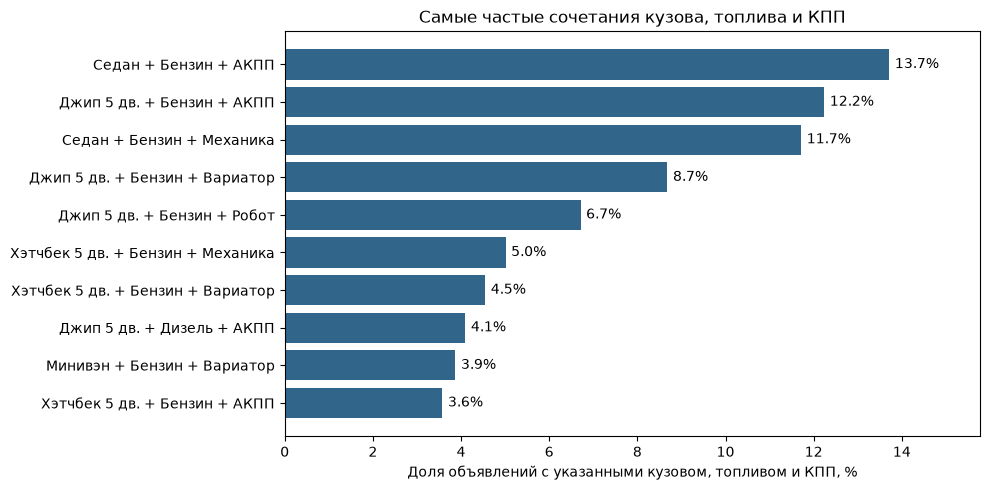

In [15]:
labels = top_combinations[["Кузов", "Топливо", "КПП"]].agg(" + ".join, axis=1)
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(labels, top_combinations["Доля, %"], color="#32658a")
ax.bar_label(bars, fmt="%.1f%%", padding=4)
ax.invert_yaxis()
ax.margins(x=0.15)
ax.set(title="Самые частые сочетания кузова, топлива и КПП",
       xlabel="Доля объявлений с указанными кузовом, топливом и КПП, %")
fig.tight_layout()
plt.show()

### Как распределены цены объявлений по бюджетному, среднему и премиум сегментам?
Границы заданы при подготовке данных: бюджетный сегмент - дешевле 1 млн ₽, средний - от 1 млн до 3 млн ₽, премиум - от 3 млн ₽. Нижняя граница включена в каждый диапазон. Доли рассчитаны среди объявлений с известной ценой.

In [17]:
price_profile = con.sql("""
    SELECT price_segment AS "Сегмент",
           COUNT(*) AS "Объявления",
           100.0 * COUNT(*) / SUM(COUNT(*)) OVER () AS "Доля, %",
           MEDIAN(price) AS "Медианная цена, ₽"
    FROM cars
    WHERE price IS NOT NULL
    GROUP BY price_segment
    ORDER BY MIN(price)
""").df()

price_profile.round(1)

,Сегмент,Объявления,"Доля, %","Медианная цена, ₽"
0,Бюджетный,259234,53.4,465000.0
1,Средний,164196,33.8,1699000.0
2,Премиум,62222,12.8,3999900.0


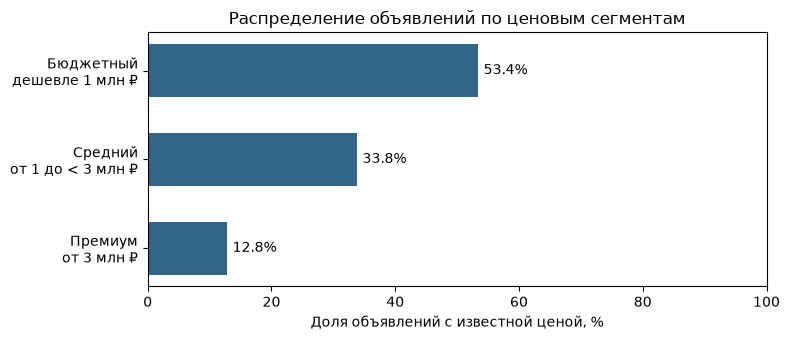

In [18]:
ranges = {
    "Бюджетный": "дешевле 1 млн ₽",
    "Средний": "от 1 до < 3 млн ₽",
    "Премиум": "от 3 млн ₽",
}
labels = [f"{segment}\n{ranges[segment]}" for segment in price_profile["Сегмент"]]
fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.barh(labels, price_profile["Доля, %"], height=0.6, color="#32658a")
ax.bar_label(bars, fmt="%.1f%%", padding=4)
ax.invert_yaxis()
ax.set(title="Распределение объявлений по ценовым сегментам",
       xlabel="Доля объявлений с известной ценой, %", xlim=(0, 100))
fig.tight_layout()
plt.show()

### Какие цвета самые популярные и как цвет связан с ценой объявления?
Популярность цвета определяется его долей среди объявлений с известным цветом. Для сравнения цен у каждого автомобиля рассчитывается отклонение от медианной цены машин той же марки, модели и года выпуска. В сравнение входят группы с известными ценами минимум двух цветов. Итог для цвета - медиана индивидуальных отклонений. Пробег, комплектация и состояние могут различаться даже внутри одной группы.

In [19]:
color_profile = con.sql("""
    WITH listings AS (
        SELECT color, price, brand, name, year
        FROM cars
        WHERE color IS NOT NULL AND lower(trim(color)) NOT IN ('', 'unknown')
    ),
    model_prices AS (
        SELECT brand, name, year, MEDIAN(price) AS model_price
        FROM listings
        WHERE price > 0 AND year IS NOT NULL
          AND lower(trim(brand)) NOT IN ('', 'unknown')
          AND lower(trim(name)) NOT IN ('', 'unknown')
        GROUP BY brand, name, year
        HAVING COUNT(DISTINCT color) >= 2
    )
    SELECT color AS "Цвет",
           COUNT(*) AS "Объявления",
           100.0 * COUNT(*) / SUM(COUNT(*)) OVER () AS "Доля, %",
           MEDIAN(price) AS "Медианная цена, ₽",
           COUNT(*) FILTER (WHERE price > 0 AND model_price IS NOT NULL) AS "В сравнении цен",
           MEDIAN(100.0 * (price / model_price - 1))
               FILTER (WHERE price > 0) AS "Отклонение, %"
    FROM listings
    LEFT JOIN model_prices USING (brand, name, year)
    GROUP BY color
    ORDER BY COUNT(*) DESC, color
""").df().set_index("Цвет")

color_profile.round(1)

,Объявления,"Доля, %","Медианная цена, ₽",В сравнении цен,"Отклонение, %"
Цвет,,,,,
Белый,119703,25.3,1250000.0,118976,0.0
Черный,96161,20.3,1200000.0,95633,0.0
Серый,87190,18.4,840000.0,86896,0.0
Серебристый,49855,10.5,685000.0,49700,0.0
Синий,36728,7.8,750000.0,36545,0.0
Красный,19451,4.1,800000.0,19323,0.0
Зеленый,18786,4.0,287500.0,18708,0.0
Коричневый,11124,2.4,1145000.0,11087,0.1
Бордовый,8068,1.7,630000.0,8036,0.0


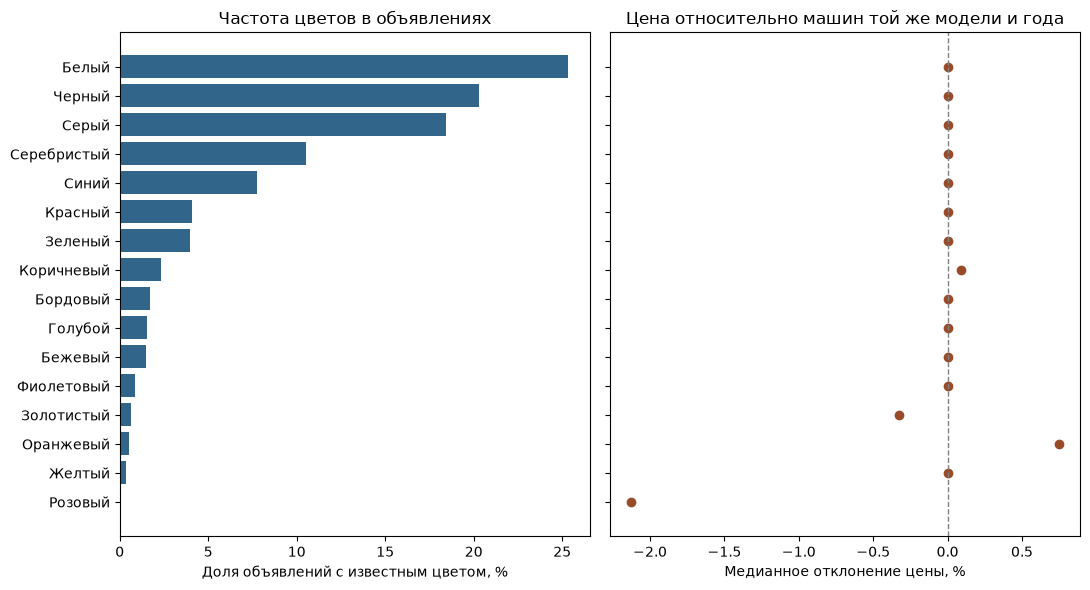

In [20]:
fig, (ax_share, ax_price) = plt.subplots(1, 2, figsize=(11, 6), sharey=True)
ax_share.barh(color_profile.index, color_profile["Доля, %"], color="#32658a")
ax_share.invert_yaxis()
ax_share.set(title="Частота цветов в объявлениях", xlabel="Доля объявлений с известным цветом, %")

ax_price.scatter(color_profile["Отклонение, %"], color_profile.index, color="#994b29")
ax_price.axvline(0, color="gray", linewidth=1, linestyle="--")
ax_price.set(title="Цена относительно машин той же модели и года",
             xlabel="Медианное отклонение цены, %")
fig.tight_layout()
plt.show()